<a href="https://colab.research.google.com/github/SHRESHTH121/Hugging-Face/blob/main/1_HuggingFacePipeline.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install transformers[sentencepiece]

In [2]:
import transformers

In [3]:
from transformers import pipeline

# **Sentiment Analysis**

In [9]:
classifier=pipeline('sentiment-analysis')
classifier('I am glad to be learning hugging face')

[transformers] No model was supplied, defaulted to distilbert/distilbert-base-uncased-finetuned-sst-2-english and revision 714eb0f.
Using a pipeline without specifying a model name and revision in production is not recommended.


Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

[{'label': 'POSITIVE', 'score': 0.9991697072982788}]

In [5]:
classifier(["Hugging face is awesome","I hate it"])

[{'label': 'POSITIVE', 'score': 0.9998747110366821},
 {'label': 'NEGATIVE', 'score': 0.9996398687362671}]

# **Zero Shot classification**

In [10]:
classifier=pipeline("zero-shot-classification")
classifier(
    "This is a course about the Transformers library",
    candidate_labels=["education", "politics", "business"])

[transformers] No model was supplied, defaulted to facebook/bart-large-mnli and revision d7645e1.
Using a pipeline without specifying a model name and revision in production is not recommended.


config.json:   0%|          | 0.00/1.15k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.63GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/515 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/899k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

{'sequence': 'This is a course about the Transformers library',
 'labels': ['education', 'business', 'politics'],
 'scores': [0.8445985913276672, 0.11197450757026672, 0.04342687129974365]}

In [11]:
classifier(
    "This is a course about Indian Politics",
    candidate_labels=["education", "politics", "business"]
)

{'sequence': 'This is a course about Indian Politics',
 'labels': ['politics', 'education', 'business'],
 'scores': [0.9885068535804749, 0.007686579134315252, 0.003806529799476266]}

# **Text Generation**

In [13]:
generator= pipeline('text-generation', model='gpt2')
generator('In this course, we will teach you how to', max_length=50, num_return_sequences=1)

config.json:   0%|          | 0.00/665 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  548MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

...

vocab.json:   0%|          | 0.00/1.04M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

[transformers] Passing `generation_config` together with generation-related arguments=({'max_length', 'num_return_sequences'}) is deprecated and will be removed in future versions. Please pass either a `generation_config` object OR all generation parameters explicitly, but not both.
[transformers] Both `max_new_tokens` (=256) and `max_length`(=50) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Ignoring clean_up_tokenization_spaces=True for BPE tokenizer GPT2Tokenizer. The clean_up_tokenization post-processing step is designed for WordPiece tokenizers and is destructive for BPE (it strips spaces before punctuation). Set clean_up_tokenization_spaces=False to suppress this warning, or set clean_up_tokenization_spaces_for_bpe_even_though_it_will_corrupt_output=True to force cleanup anyway.


[{'generated_text': 'In this course, we will teach you how to design and create a beautiful, modern virtual reality game.\n\nThe goal of the course is to show you how to create a game that will have high quality graphics, sound, and gameplay in an elegant, realistic manner. You will be able to create your game with all the features of the original Wii U game, as well as with the Wii Classic, Wii U GamePad and Wii U GamePad Pro, along with various other devices, such as your own console, tablet, computer, portable or mobile device. We will also teach you how to create a game with a high resolution high quality sound, which will sound amazing.\n\nWe will also provide you with a set of tutorials for creating a game that will have high quality graphics, sound, and gameplay. We will include a short video, which we will show you about how to create a game that will have high quality graphics, sound, and gameplay in an elegant, realistic manner. You will be able to create your game with all t

# **Mask Filling**

In [15]:
unmasker=pipeline('fill-mask')
unmasker("This course will teach you all about <mask> models.", top_k=2)
#top_k displays number of possibilities you want to be displayed

[transformers] No model was supplied, defaulted to distilbert/distilroberta-base and revision fb53ab8.
Using a pipeline without specifying a model name and revision in production is not recommended.


Loading weights:   0%|          | 0/106 [00:00<?, ?it/s]

[transformers] RobertaForMaskedLM LOAD REPORT from: distilbert/distilroberta-base
Key                         | Status     |  | 
----------------------------+------------+--+-
roberta.pooler.dense.weight | UNEXPECTED |  | 
roberta.pooler.dense.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


[{'score': 0.19619713723659515,
  'token': 30412,
  'token_str': ' mathematical',
  'sequence': 'This course will teach you all about mathematical models.'},
 {'score': 0.040527280420064926,
  'token': 38163,
  'token_str': ' computational',
  'sequence': 'This course will teach you all about computational models.'}]

# **Image Classification**

In [16]:
image_classifier=pipeline('image-classification')
image_classifier("https://huggingface.co/datasets/huggingface/documentation-images/resolve/main/pipeline-cat-chonk.jpeg")

[transformers] No model was supplied, defaulted to google/vit-base-patch16-224 and revision 3f49326.
Using a pipeline without specifying a model name and revision in production is not recommended.


config.json:   0%|          | 0.00/69.7k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  346MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/200 [00:00<?, ?it/s]

preprocessor_config.json:   0%|          | 0.00/160 [00:00<?, ?B/s]

[{'label': 'lynx, catamount', 'score': 0.4333980977535248},
 {'label': 'cougar, puma, catamount, mountain lion, painter, panther, Felis concolor',
  'score': 0.03480524197220802},
 {'label': 'snow leopard, ounce, Panthera uncia',
  'score': 0.03240472823381424},
 {'label': 'Egyptian cat', 'score': 0.023974046111106873},
 {'label': 'tiger cat', 'score': 0.022902466356754303}]

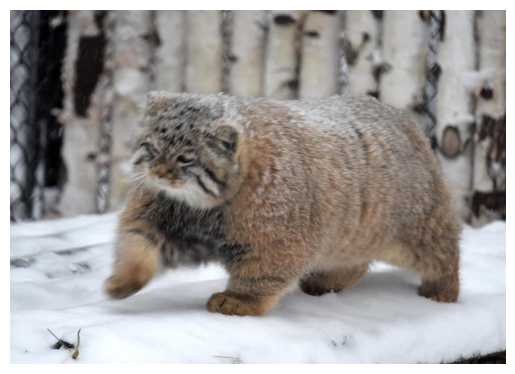

In [17]:
from PIL import Image
import requests
from io import BytesIO
import matplotlib.pyplot as plt

image_url = "https://huggingface.co/datasets/huggingface/documentation-images/resolve/main/pipeline-cat-chonk.jpeg"
response = requests.get(image_url)
img = Image.open(BytesIO(response.content))

plt.imshow(img)
plt.axis('off') # Hide axes
plt.show()

# **Automatic Speech Recognition**

In [18]:
transcriber=pipeline("automatic-speech-recognition")

[transformers] No model was supplied, defaulted to facebook/wav2vec2-base-960h and revision 22aad52.
Using a pipeline without specifying a model name and revision in production is not recommended.


config.json:   0%|          | 0.00/1.60k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  378MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/212 [00:00<?, ?it/s]

[transformers] Wav2Vec2ForCTC LOAD REPORT from: facebook/wav2vec2-base-960h
Key                        | Status  | 
---------------------------+---------+-
wav2vec2.masked_spec_embed | MISSING | 

Notes:
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


tokenizer_config.json:   0%|          | 0.00/163 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/291 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/85.0 [00:00<?, ?B/s]

preprocessor_config.json:   0%|          | 0.00/159 [00:00<?, ?B/s]

In [20]:
transcriber("https://huggingface.co/datasets/Narsil/asr_dummy/resolve/main/mlk.flac")

{'text': 'I HAVE A DREAM BUT ONE DAY THIS NATION WILL RISE UP LIVE UP THE TRUE MEANING OF ITS TREES'}

In [21]:
from IPython.display import Audio

audio_url = "https://huggingface.co/datasets/Narsil/asr_dummy/resolve/main/mlk.flac"
Audio(audio_url)